# PathSnap model 04: Random Forest

*Family: Ensemble (bagging)*

**What every model in this project does.** For each GPS fix we already have a short list of *candidate* road arcs
(all arcs within 50 m, at least 5). Each (fix, candidate) pair is one row with 13 features (distance, heading
difference, …) and a label `y` = 1 if the candidate is the fix's true arc, else 0. The model learns
**P(candidate is the true arc | features)**. For each fix, the candidate with the highest probability is the
prediction. Every model notebook uses the same data, folds and metrics from `pathsnap_common.py`, so the numbers are
directly comparable.

**Metrics used below** (full definitions in the report):
- **Top-1 accuracy** (primary): share of fixes whose highest-probability candidate is the true arc.
- **Macro F1**: per trip, the F1-score of each road arc treated as a class, averaged over arcs (so short, rarely
  visited arcs count as much as long ones), then averaged over trips.
- **Log loss**: how good the probabilities are (lower is better); punishes confident mistakes.
- **Precision / recall / F1 / confusion matrix**: candidate level, "is this the true arc?" with threshold 0.5.
- **Route continuity**: share of consecutive fixes whose predicted arcs are the same or connected within 3 arcs.
- **Route F1**: length-weighted overlap between the set of predicted arcs and the reference route.

## 1. What the algorithm does

A **decision tree** asks a sequence of yes/no questions about the features ("is `heading_diff` < 40°?") and ends in
a leaf that holds the share of true arcs among the training rows that reached it. A single deep tree memorises
noise. A **random forest** trains many trees, each on a bootstrap sample (random rows drawn with replacement) and
each split choosing from a random subset of features, then averages their probabilities ("bagging").

## 2. Why we tried it for PathSnap, strengths and limitations

- Trees handle exactly the structure our features have: thresholds ("within ~10 m"), interactions ("heading only
  matters when moving"), mixed scales and integer codes, with no scaling needed.
- **Strengths:** strong non-linear model, robust to outliers and correlated features, little tuning, averaging many
  trees reduces variance (overfitting).
- **Limitations:** large model files (hundreds of trees), slower prediction than a linear model, probabilities can be
  under-confident near 0/1 because they are averages of leaf frequencies, and deep trees can still fit noise
  in the training trips.

### Hyperparameters (initial values) and training objective

| Hyperparameter | Initial value | Meaning |
|---|---|---|
| `n_estimators` | 200 | number of trees |
| `max_features` | sqrt (≈ 4 of 13) | features considered at each split; adds randomness between trees |
| `min_samples_leaf` | 20 | each leaf must contain ≥ 20 rows; limits memorisation |
| `max_depth` | None | trees grow until the leaf limit stops them |
| `bootstrap` | True | each tree sees a resampled training set |
| `FRAC` | 0.25 | 25% of training fixes (≈ 360 k rows per fold) to keep time and memory reasonable |


**Objective:** each split greedily minimises **Gini impurity** (how mixed the classes in a node are). There is no
global loss and no epoch-wise training history.

### Setup: load the candidate tables

In [1]:
import sys, time, json
sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathsnap_common import *

train = load_partition("train")          # every candidate row of the 80 train trips
test = load_partition("student_test")    # every candidate row of the 10 student_test trips
print(f"train: {len(train):,} rows ({train.keep_train.sum():,} with reliable labels) | student_test: {len(test):,} rows")
print("features:", FEATURES)

train: 2,103,209 rows (1,801,387 with reliable labels) | student_test: 222,004 rows
features: ['dist', 'dist_rank', 'dist_gap', 'heading_diff', 'speed', 'along_t', 'arc_len', 'has_twin', 'junction_deg', 'n_cand20', 'n_cand50', 'nbr_dist', 'conn_prev']


### Model definition

In [2]:
from sklearn.ensemble import RandomForestClassifier

NAME, TITLE, FAMILY = "random_forest", "Random Forest", "Ensemble (bagging)"
FRAC, SAVE_MODEL = 0.25, False   # the fitted forest is ~hundreds of MB; it is re-creatable from this notebook
CONFIG = dict(n_estimators=200, max_features="sqrt", min_samples_leaf=20, max_depth=None, bootstrap=True,
              criterion="gini", train_frac=FRAC, random_state=SEED)


def make_model():
    return RandomForestClassifier(n_estimators=200, max_features="sqrt", min_samples_leaf=20, n_jobs=8,
                                  random_state=SEED)

## 3. Cross-validation (GroupKFold by trip, 5 folds)

The 80 train trips are split into 5 groups of 16. Each fold trains on 64 trips and predicts the 16 held-out trips,
so the model is always scored on trips it has never seen (fixes of one trip are nearly identical, so mixing them
would inflate scores). Training uses a random `FRAC` share of the reliable-label fixes of the 64 trips (all
candidates of a chosen fix stay together); prediction covers every candidate of the held-out trips.
We also score the model on (a sample of) the fixes it was trained on: a large train/validation gap means
**overfitting**; low scores on both mean **underfitting**.

[random_forest] fold 1: train top-1 0.8942 | val top-1 0.8597 | val log loss 0.0788 | fit 71s


[random_forest] fold 2: train top-1 0.8882 | val top-1 0.8998 | val log loss 0.0553 | fit 75s


[random_forest] fold 3: train top-1 0.9044 | val top-1 0.8527 | val log loss 0.0700 | fit 82s


[random_forest] fold 4: train top-1 0.8914 | val top-1 0.9144 | val log loss 0.0458 | fit 74s


[random_forest] fold 5: train top-1 0.9009 | val top-1 0.8300 | val log loss 0.0884 | fit 74s


CV done in 408 s


,fold,train_rows,fit_s,train_top1,val_top1,train_logloss,val_logloss,val_macro_f1,val_precision,val_recall,val_f1,val_continuity,val_route_f1
0,1,359965,70.6191,0.8942,0.8597,0.0524,0.0788,0.6954,0.8888,0.8175,0.8517,0.9590,0.8433
1,2,362252,74.7894,0.8882,0.8998,0.0573,0.0553,0.7979,0.9200,0.8580,0.8880,0.9431,0.9039
2,3,358590,82.3395,0.9044,0.8527,0.0521,0.0700,0.7195,0.8874,0.8108,0.8474,0.9736,0.8656
3,4,359772,74.0870,0.8914,0.9144,0.0580,0.0458,0.8011,0.9347,0.8695,0.9009,0.9720,0.9054
4,5,359537,73.5044,0.9009,0.8300,0.0498,0.0884,0.6953,0.8562,0.7942,0.8240,0.9802,0.8374


mean ± std  val top-1 87.13% ± 3.48% | val macro F1 0.7418 ± 0.0536 | val log loss 0.0676


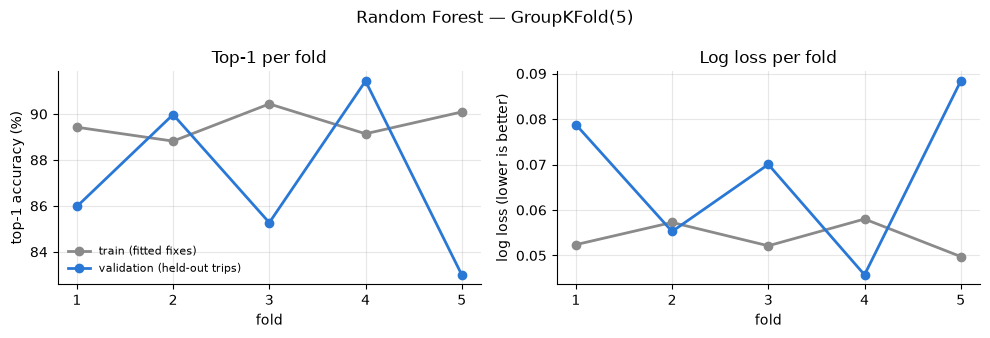

In [3]:
t0 = time.time()
cv, oof, cv_models = run_cv(make_model, train, FRAC, label=NAME)
print(f"CV done in {time.time() - t0:.0f} s")
show = ["fold", "train_rows", "fit_s", "train_top1", "val_top1", "train_logloss", "val_logloss", "val_macro_f1",
        "val_precision", "val_recall", "val_f1", "val_continuity", "val_route_f1"]
display(cv[show].round(4))
print("mean ± std  val top-1 {:.2%} ± {:.2%} | val macro F1 {:.4f} ± {:.4f} | val log loss {:.4f}".format(
    cv.val_top1.mean(), cv.val_top1.std(), cv.val_macro_f1.mean(), cv.val_macro_f1.std(), cv.val_logloss.mean()))
fig = plot_cv(cv, TITLE + " — GroupKFold(5)")
(OUT_DIR / NAME).mkdir(parents=True, exist_ok=True)
fig.savefig(OUT_DIR / NAME / "fig_cv.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Final fit on all 80 train trips and evaluation on student_test

Refit with the same recipe on the reliable-label fixes of all 80 train trips, then score every candidate of the 10
student_test trips. student_test is used only for this development-stage comparison, never for training.
**Inference time** is the time `predict_proba` takes for all student_test candidates, per 1 000 GPS fixes
(features are already computed; feature building is the same for every model).

,student_test
top1,0.8869
top1_all,0.8656
macro_f1,0.7605
logloss,0.0541
precision,0.9069
recall,0.8565
f1,0.8810
continuity,0.9748
route_f1,0.9084
fit_s,106.9347


,trip,n_fix,top1,macro_f1,continuity,route_f1
0,00000000,2503,0.9393,0.7108,0.9836,0.9566
1,00000007,1354,0.9830,0.9485,0.9985,0.9840
2,00000009,1049,0.8618,0.7777,0.9609,0.8744
3,00000040,2995,0.9379,0.7874,0.9923,0.9217
4,00000052,262,0.9580,0.8308,0.9808,0.9517
5,00000056,3958,0.8982,0.8250,0.9464,0.9189
6,00000065,768,0.8385,0.7173,0.9752,0.9038
7,00000076,1486,0.8694,0.6360,0.9522,0.8501
8,00000077,3911,0.7690,0.6057,0.9913,0.7911
9,00000091,874,0.8627,0.7654,0.9599,0.9315


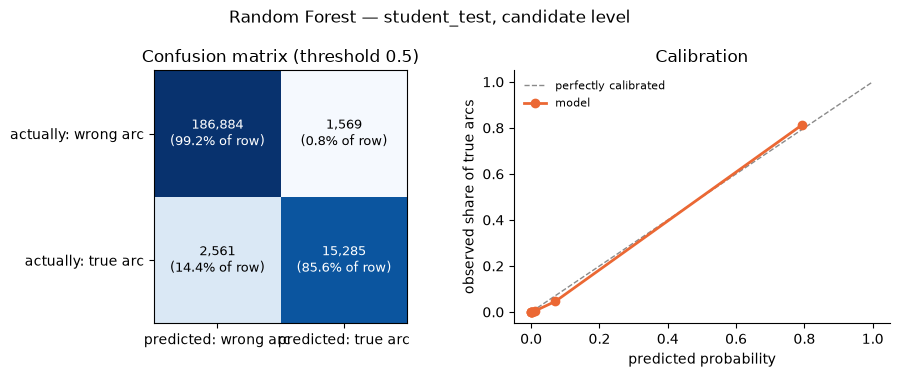

In [4]:
final_model, p_test, test_res, test_preds = fit_and_test(make_model, train, test, FRAC)
keys = ["top1", "top1_all", "macro_f1", "logloss", "precision", "recall", "f1", "continuity", "route_f1",
        "fit_s", "predict_ms_per_1k_fixes"]
display(pd.Series({k: test_res[k] for k in keys}).to_frame("student_test").round(4))
display(pd.DataFrame(test_res["per_trip"]).assign(trip=lambda d: [trips("student_test")[t] for t in d.tidx])
        .assign(top1=lambda d: d.correct_kept / d.n_kept)[["trip", "n_fix", "top1", "macro_f1", "continuity", "route_f1"]].round(4))
fig = plot_confusion_and_calibration(test, p_test, TITLE)
fig.savefig(OUT_DIR / NAME / "fig_confusion_calibration.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Impurity-based feature importance

How much each feature reduced Gini impurity across all trees (biased towards continuous features, so we read it
together with the permutation importance from `feature_engineering.ipynb`).

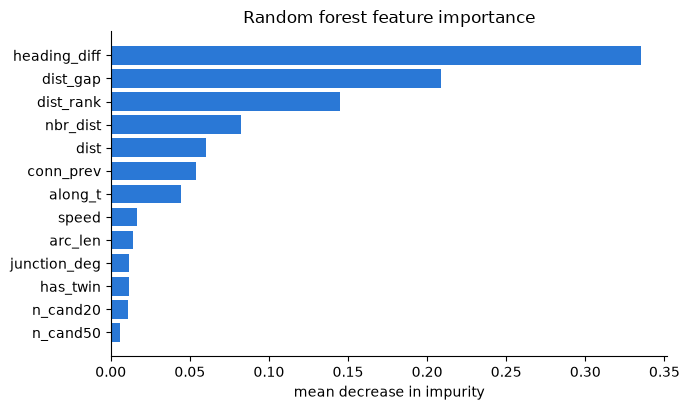

In [5]:
imp = pd.Series(final_model.feature_importances_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(imp.index, imp.values, color=BLUE); ax.set_xlabel("mean decrease in impurity")
ax.set_title("Random forest feature importance"); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(OUT_DIR / NAME / "fig_importance.png", dpi=150); plt.show()

## Save results

Writes `models_out/<model>/results.json` (config, CV mean/std, student_test metrics), the per-fold table, per-trip student_test table, out-of-fold probabilities (used by the comparison and HMM notebooks) and the fitted model.

In [6]:
summary = save_results(NAME, FAMILY, CONFIG, cv, test_res, model=final_model if SAVE_MODEL else None,
                       oof=oof, p_test=p_test)
print(json.dumps({k: summary[k] for k in ["name", "family", "config"]}, indent=1))
print("saved to", OUT_DIR / NAME)

{
 "name": "random_forest",
 "family": "Ensemble (bagging)",
 "config": {
  "n_estimators": 200,
  "max_features": "sqrt",
  "min_samples_leaf": 20,
  "max_depth": null,
  "bootstrap": true,
  "criterion": "gini",
  "train_frac": 0.25,
  "random_state": 42
 }
}
saved to /home/av8/Documents/ML/Hackathon/models_out/random_forest
